# LPAD Crimes — Agrupamento de ocorrências (K-Modes) · versão revisada

**Projeto Integrador III — Ciência de Dados e Machine Learning, CEUB**

**Posição na cadeia:** `01 limpeza` → `data/processed/lapd_clean.csv` → **`02 clusterização`** → `data/processed/amostra_clusters.csv` → `03 visualizações`. A entrada é o CSV gerado pelo notebook de limpeza (corte de data, sentinelas e ausências estruturais já tratados lá); aqui ficam só a engenharia de atributos do agrupamento e o agrupamento em si.

Este notebook substitui `03_clusters_kmodes.ipynb`. Ele implementa as correções E1–E5 do relatório parcial, corrige erros de código da versão anterior e acrescenta novas métricas de validação de agrupamento.

### O que mudou em relação à versão anterior

| # | Problema na versão anterior | Correção aqui |
|---|---|---|
| 1 | `ValueError: Input contains NaN`: só `Mocodes`, `Vict Sex` e `Vict Descent` tinham os nulos tratados | Ausências estruturais viram categorias explícitas (`SEM_ARMA`, `NAO_APLICAVEL` etc.) |
| 2 | Três `sample()` encadeados (0,20 × 0,25 × 0,10 = 0,5% da base) e `[:10000]` não aleatório (**E1**) | Uma única amostra aleatória com semente fixa |
| 3 | `dropna` em `Vict Sex`/`Vict Descent`/`Mocodes` eliminava ~99% de `VEHICLE - STOLEN` (**E2**) | Nenhum registro é descartado por ausência estrutural |
| 4 | Colunas quase únicas (`LAT`, `LON`, `LOCATION`, datas, `Mocodes` como texto) no K-Modes (**E3**) | Apenas atributos categóricos de cardinalidade controlada; `Mocodes` tratado à parte (Seção 9) |
| 5 | `Crm Cd` + `Crm Cd Desc` + `Crm Cd 1`, `Premis Cd` + `Premis Desc`, `Crm Cd 2–4` quase constantes (**E4**) | Um único atributo por conceito |
| 6 | Variáveis demográficas da vítima **como entrada** → partição circular (relatório, 6.1 e 9.2) | Agrupamento só com atributos do **fato criminal**; demografia, área e desfecho entram **depois**, como variáveis de descrição (responde a PP2 sem circularidade) |
| 7 | `init='Cao'` com `n_init=5` (Cao é determinístico: as 5 execuções são idênticas) e `n_init=5` insuficiente para Huang | Huang com `n_init` maior; Cao rodado uma vez, como comparação |
| 8 | Saídas de sessões diferentes (**E5**); função de cotovelo redefinida sem ser executada | Notebook linear; rodar com *Ambiente de execução → Reiniciar e executar tudo* |
| 9 | Gráfico "Crm Cd 1 por Cluster" usava `df_cluster` em vez de `df_cluster_crimes`; título "Crm Cd 3" no gráfico de `Crm Cd 2`; barras empilhadas com 100+ categorias | Perfis por *lift* e mapas de calor legíveis |
| 10 | Série não truncada em 29/02/2024, apesar da decisão metodológica do relatório (Seção 3.4) | Corte aplicado, porque a composição dos registros muda após a migração para o NIBRS |
| 11 | Matriz de V de Cramér calculada sobre datas e `LOCATION`, com a correção dividindo por zero em tabelas degeneradas | V de Cramér só entre as variáveis analíticas, com proteção contra divisão por zero |

### Métricas e análises novas

1. **Modelo nulo por permutação**: testa se existe estrutura de agrupamento acima do acaso (a pergunta que o relatório deixou em aberto na Seção 6.2)
2. **Silhueta com distância de Hamming**
3. **Estabilidade por reamostragem** (ARI médio entre execuções)
4. **Detecção automática do cotovelo** (em vez da leitura visual)
5. **Perfis de cluster por *lift***, no lugar de barras empilhadas
6. **Associação *a posteriori*** entre cluster e área, perfil da vítima e desfecho: V de Cramér, AMI e resíduos padronizados
7. **Agrupamento de modus operandi** (`Mocodes` binarizado → TF-IDF → SVD → K-Means)

In [1]:
!pip install -q kmodes

In [2]:
import os
import warnings
from itertools import combinations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap
from scipy.stats import chi2_contingency
from kmodes.kmodes import KModes
from sklearn.metrics import adjusted_mutual_info_score, adjusted_rand_score, silhouette_score
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD
from sklearn.preprocessing import Normalizer
from sklearn.cluster import KMeans

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)

## 1. Configuração

Todos os parâmetros ficam aqui. Para uma execução rápida de teste, reduza `N_AMOSTRA` e `N_BUSCA_K`.

In [3]:
SEED = 42

CAMINHO_LIMPO = "data/processed/lapd_clean.csv"   # saída do notebook 01 (limpeza)
CAMINHO_MO = "data/raw/mo_codes.csv"      # opcional: colunas 'codigo','descricao' (tabela de MO codes do LAPD)
DIR_FIGURAS = "docs/figuras"
DIR_PROCESSADOS = "data/processed"

DATA_CORTE = "2024-02-29"   # quebra estrutural (relatório, Seção 3); o corte é aplicado na limpeza e só conferido aqui

N_AMOSTRA = 50_000          # amostra aleatória de trabalho (E1)
N_BUSCA_K = 15_000          # subamostra usada na busca de k (K-Modes é O(n·k) por iteração)
N_SILHUETA = 4_000          # silhueta é O(n²): calculada em subamostra
K_RANGE = list(range(2, 13))
N_INIT = 10                 # reinicializações do Huang (relatório pede >= 20 na versão final)
N_NULO = 3                  # repetições do modelo nulo
N_ESTAB = 4                 # repetições do teste de estabilidade (cada uma com N_INIT reinícios)

TOP_CRIME = 25              # categorias mantidas; o resto vira "OUTROS"
TOP_LOCAL = 15

os.makedirs(DIR_FIGURAS, exist_ok=True)
os.makedirs(DIR_PROCESSADOS, exist_ok=True)
rng = np.random.default_rng(SEED)

In [4]:
# Estilo dos gráficos: eixos discretos, grade leve, paleta fixa
AZUL, LARANJA, CINZA, TINTA, TINTA2 = "#2a78d6", "#eb6834", "#898781", "#0b0b0b", "#52514e"
SEQ = LinearSegmentedColormap.from_list("seq", ["#f4f8fd", "#9ec5f4", "#3987e5", "#1c5cab", "#0d366b"])
DIV = LinearSegmentedColormap.from_list("div", ["#1c5cab", "#86b6ef", "#f0efec", "#ef9a99", "#b8302f"])

plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": CINZA, "axes.labelcolor": TINTA2, "xtick.color": TINTA2, "ytick.color": TINTA2,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6,
    "axes.titleweight": "bold", "axes.titlesize": 12, "font.size": 10,
    "lines.linewidth": 2, "lines.markersize": 6,
})

def salvar(nome):
    plt.savefig(f"{DIR_FIGURAS}/{nome}.png", dpi=150, bbox_inches="tight")

## 2. Carga

Lê o CSV produzido pelo notebook de limpeza (`data/processed/lapd_clean.csv`). Todas as colunas são lidas como texto, para que `Crm Cd` não vire `float` por causa dos nulos.

In [5]:
if not os.path.exists(CAMINHO_LIMPO):
    raise FileNotFoundError(
        f"{CAMINHO_LIMPO} não existe. Rode antes o notebook 01 (limpeza), a partir da mesma pasta de trabalho.")

df_raw = pd.read_csv(CAMINHO_LIMPO, dtype=str)
df_raw.columns = df_raw.columns.str.strip()

# Contrato com o notebook de limpeza: colunas que ele exporta
OBRIGATORIAS = ["DR_NO", "DATE OCC", "DATETIME OCC", "AREA NAME", "Crm Cd", "Crm Cd Desc", "Mocodes",
                "Vict Age", "Vict Sex", "Vict Descent", "Premis Desc", "Weapon Used Cd", "Weapon Desc",
                "Status", "LAT", "LON"]
faltando = [c for c in OBRIGATORIAS if c not in df_raw.columns]
assert not faltando, f"Colunas ausentes em {CAMINHO_LIMPO}: {faltando}"
print(f"{len(df_raw):,} registros × {df_raw.shape[1]} colunas")

913,647 registros × 24 colunas


## 3. Tratamento

Segue o Apêndice B do relatório parcial. O corte de data, o tratamento de valores sentinela e a conversão das ausências estruturais em categorias já foram feitos no notebook de limpeza (E2: nenhum registro é descartado por ausência estrutural). Aqui o tratamento se resume a montar os atributos do agrupamento e as variáveis de descrição.

In [6]:
df = df_raw.copy()
df["DATA_OCC"] = pd.to_datetime(df["DATE OCC"], errors="coerce")
df["DATETIME_OCC"] = pd.to_datetime(df["DATETIME OCC"], errors="coerce")

# Conferência: o corte foi aplicado na limpeza
assert df["DATA_OCC"].notna().all(), "DATE OCC com valores inválidos"
assert df["DATA_OCC"].max() <= pd.Timestamp(DATA_CORTE), f"há registros posteriores a {DATA_CORTE}: rode a limpeza de novo"
print(f"Base limpa: {len(df):,} registros, até {df['DATA_OCC'].max():%Y-%m-%d}")

# Amostra aleatória única (E1)
df = df.sample(n=min(N_AMOSTRA, len(df)), random_state=SEED).reset_index(drop=True)
print(f"Amostra de trabalho: {len(df):,}")

Base limpa: 913,647 registros, até 2024-02-29
Amostra de trabalho: 50,000


In [7]:
def faixas(valores, bins, labels, ausente):
    # pd.cut com rótulo explícito para ausentes (funciona no pandas 2 e 3)
    c = pd.cut(valores, bins=bins, labels=labels)
    return c.cat.add_categories([ausente]).fillna(ausente).astype(str)

def top_n(s, n, outros="OUTROS"):
    manter = s.value_counts().index[:n]
    return s.where(s.isin(manter), outros)

# ---------- Atributos do FATO CRIMINAL (entram no K-Modes) ----------
# CRIME: usa Crm Cd (não Crm Cd 1, que diverge em ~0,2% dos casos), exibido pela descrição
desc_crime = (df.dropna(subset=["Crm Cd", "Crm Cd Desc"])
                .drop_duplicates("Crm Cd").set_index("Crm Cd")["Crm Cd Desc"])
df["CRIME"] = top_n(df["Crm Cd"].map(desc_crime).fillna("DESCONHECIDO"), TOP_CRIME)

df["LOCAL"] = top_n(df["Premis Desc"].fillna("NAO_INFORMADO"), TOP_LOCAL)

# ARMA: famílias de código do LAPD (1xx fogo, 2xx branca, 3xx objeto, 400 força física, 5xx outros)
cod_arma = pd.to_numeric(df["Weapon Used Cd"], errors="coerce")
df["ARMA"] = np.select(
    [cod_arma.isna(), cod_arma < 200, cod_arma < 300, cod_arma < 400, cod_arma < 500],
    ["SEM_ARMA", "ARMA_DE_FOGO", "ARMA_BRANCA", "OBJETO", "FORCA_FISICA"],
    default="OUTRA/DESCONHECIDA")

# PERÍODO: faixas do dia (39% de TIME OCC termina em :00, relatório 4.3)
hora = df["DATETIME_OCC"].dt.hour   # NaN (horário inválido) vira SEM_HORA
df["PERIODO"] = faixas(hora, [-1, 5, 11, 17, 23], ["MADRUGADA", "MANHA", "TARDE", "NOITE"], "SEM_HORA")
df["DIA"] = np.where(df["DATA_OCC"].dt.dayofweek >= 5, "FIM_DE_SEMANA", "DIA_UTIL")

# ---------- Variáveis de DESCRIÇÃO (não entram no K-Modes) ----------
df["AREA_NOME"] = df["AREA NAME"].str.strip()

sexo = df["Vict Sex"].str.strip().fillna("NAO_APLICAVEL")
df["SEXO_VIT"] = sexo.where(sexo.isin(["M", "F", "NAO_APLICAVEL"]), "DESCONHECIDO")   # X, H, "-"

desc = df["Vict Descent"].str.strip().fillna("NAO_APLICAVEL")
desc = desc.where(~desc.isin(["X", "-", ""]), "DESCONHECIDO")
df["ASCEND_VIT"] = top_n(desc, 8)

idade = pd.to_numeric(df["Vict Age"], errors="coerce")
idade = idade.where((idade > 0) & (idade <= 100))                 # 0 e negativos são sentinela
df["FAIXA_IDADE"] = faixas(idade, [0, 17, 29, 44, 64, 100], ["0-17", "18-29", "30-44", "45-64", "65+"], "NAO_INFORMADA")

df["PRISAO"] = np.where(df["Status"].isin(["AA", "JA"]), "PRISAO", "SEM_PRISAO")
df["ANO"] = df["DATA_OCC"].dt.year.astype(str)

FEATS = ["CRIME", "LOCAL", "ARMA", "PERIODO", "DIA"]
DESCRITIVAS = ["AREA_NOME", "SEXO_VIT", "ASCEND_VIT", "FAIXA_IDADE", "PRISAO", "ANO"]

nulos = df[FEATS + DESCRITIVAS].isna().sum()
assert nulos.sum() == 0, f"ainda há NaN: {nulos[nulos > 0].to_dict()}"
df[FEATS].head()

,CRIME,LOCAL,ARMA,PERIODO,DIA
0,BATTERY - SIMPLE ASSAULT,PARKING LOT,FORCA_FISICA,TARDE,DIA_UTIL
1,BURGLARY FROM VEHICLE,STREET,SEM_ARMA,MANHA,DIA_UTIL
2,THEFT PLAIN - PETTY ($950 & UNDER),OUTROS,SEM_ARMA,MANHA,DIA_UTIL
3,"THEFT-GRAND ($950.01 & OVER)EXCPT,GUNS,FOWL,LI...",OUTROS,OUTRA/DESCONHECIDA,TARDE,DIA_UTIL
4,OUTROS,STREET,SEM_ARMA,NOITE,FIM_DE_SEMANA


In [8]:
# Conferência da agregação de armas: as descrições mais comuns de cada família
(df.dropna(subset=["Weapon Desc"])
   .groupby("ARMA")["Weapon Desc"]
   .agg(lambda s: " | ".join(s.value_counts().index[:3])))

,Weapon Desc
ARMA,
ARMA_BRANCA,KNIFE WITH BLADE 6INCHES OR LESS | OTHER KNIFE...
ARMA_DE_FOGO,HAND GUN | SEMI-AUTOMATIC PISTOL | UNKNOWN FIR...
FORCA_FISICA,"STRONG-ARM (HANDS, FIST, FEET OR BODILY FORCE)"
OBJETO,VEHICLE | PIPE/METAL PIPE | STICK
OUTRA/DESCONHECIDA,UNKNOWN WEAPON/OTHER WEAPON | VERBAL THREAT | ...


### 3.1 Diagnóstico dos atributos de entrada

Replica a tabela de cardinalidade do relatório (Seção 6.2) para os atributos novos. Nenhum deve ter moda acima de ~95% (quase constante, E4) nem centenas de níveis (E3).

In [9]:
diag = pd.DataFrame({
    "niveis": df[FEATS].nunique(),
    "moda": [df[c].mode()[0] for c in FEATS],
    "moda_cobre_%": [(df[c].value_counts(normalize=True).iloc[0] * 100).round(1) for c in FEATS],
})
diag

,niveis,moda,moda_cobre_%
CRIME,26,VEHICLE - STOLEN,10.4
LOCAL,16,STREET,25.2
ARMA,6,SEM_ARMA,65.4
PERIODO,4,TARDE,32.5
DIA,2,DIA_UTIL,71.6


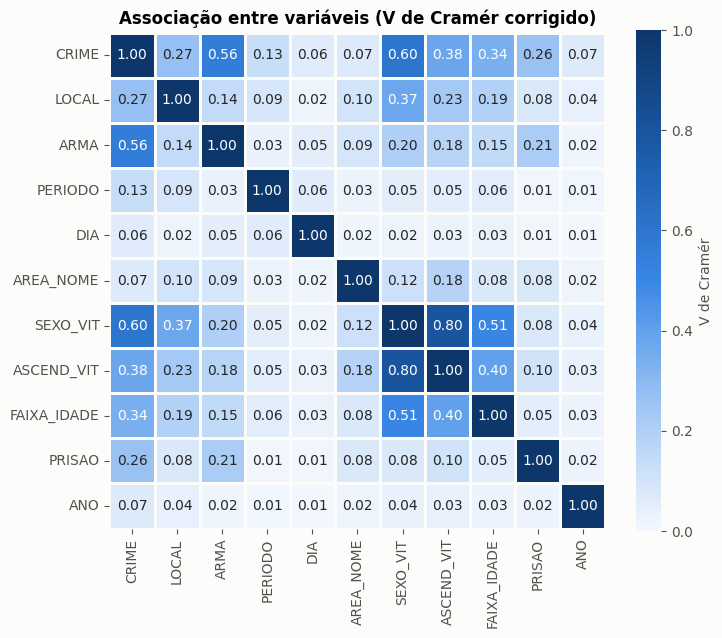

In [10]:
def cramers_v(x, y):
    # V de Cramér com correção de viés (Bergsma, 2013)
    tab = pd.crosstab(x, y)
    if min(tab.shape) < 2:
        return np.nan
    chi2 = chi2_contingency(tab, correction=False)[0]
    n = tab.values.sum()
    r, k = tab.shape
    phi2 = max(0, chi2 / n - (k - 1) * (r - 1) / (n - 1))
    rc, kc = r - (r - 1) ** 2 / (n - 1), k - (k - 1) ** 2 / (n - 1)
    den = min(kc - 1, rc - 1)
    return np.sqrt(phi2 / den) if den > 0 else np.nan

def matriz_v(dados, cols):
    m = pd.DataFrame(np.eye(len(cols)), index=cols, columns=cols)
    for a, b in combinations(cols, 2):
        m.loc[a, b] = m.loc[b, a] = cramers_v(dados[a], dados[b])
    return m

mv = matriz_v(df, FEATS + DESCRITIVAS)
fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(mv, annot=True, fmt=".2f", cmap=SEQ, vmin=0, vmax=1, square=True,
            linewidths=2, linecolor="#fcfcfb", cbar_kws={"label": "V de Cramér"}, ax=ax)
ax.set_title("Associação entre variáveis (V de Cramér corrigido)")
ax.grid(False)
salvar("01_cramers_v")
plt.show()

## 4. Escolha de k

A versão anterior escolheu k=7 olhando o cotovelo, mas o relatório mostrou que a curva **não tem cotovelo**. Aqui a escolha passa a ter quatro evidências independentes:

| Métrica | Pergunta que responde | Leitura |
|---|---|---|
| **Custo** (Huang e Cao) + cotovelo automático | Onde o ganho marginal de custo cai? | Joelho da curva |
| **Ganho sobre o modelo nulo** | A redução de custo é maior que a obtida em dados **sem estrutura**? | 0 = nenhuma estrutura; quanto maior, melhor |
| **Silhueta (Hamming)** | Os registros estão mais próximos do próprio cluster que do vizinho? | −1 a 1; perto de 0 = clusters sobrepostos |
| **Estabilidade (ARI)** | A partição se repete com outra amostra e outra semente? | 1 = idêntica; abaixo de ~0,6 = instável |

O **modelo nulo** embaralha cada coluna de forma independente. As frequências de cada categoria ficam iguais, mas qualquer associação entre colunas é destruída. Se o K-Modes reduz o custo nos dados reais tanto quanto nos embaralhados, a partição está só fatiando as distribuições marginais, e não encontrando grupos.

In [11]:
idx_busca = rng.choice(len(df), size=min(N_BUSCA_K, len(df)), replace=False)
X_busca = df.loc[idx_busca, FEATS].to_numpy()

# Versão numérica (códigos inteiros) para a silhueta com métrica de Hamming
cods = {c: {v: i for i, v in enumerate(sorted(df[c].unique()))} for c in FEATS}
def codificar(X):
    return np.column_stack([pd.Series(X[:, j]).map(cods[c]).to_numpy() for j, c in enumerate(FEATS)])

def embaralhar(X, gen):
    return np.column_stack([gen.permutation(X[:, j]) for j in range(X.shape[1])])

def ajustar(X, k, init="Huang", n_init=N_INIT, seed=SEED):
    return KModes(n_clusters=k, init=init, n_init=n_init if init == "Huang" else 1,
                  random_state=seed, n_jobs=-1).fit(X)

def joelho(ks, custos):
    # Kneedle simplificado: ponto de maior distância à reta entre as extremidades
    x = (np.array(ks) - ks[0]) / (ks[-1] - ks[0])
    y = (np.array(custos) - min(custos)) / (max(custos) - min(custos))
    return ks[int(np.argmax(np.abs((1 - x) - y)))]

In [12]:
X_busca_cod = codificar(X_busca)
sub_sil = rng.choice(len(X_busca), size=min(N_SILHUETA, len(X_busca)), replace=False)
custo_k1 = sum((X_busca[:, j] != pd.Series(X_busca[:, j]).mode()[0]).sum() for j in range(X_busca.shape[1]))

linhas = []
for k in K_RANGE:
    km_h = ajustar(X_busca, k, "Huang")
    km_c = ajustar(X_busca, k, "Cao")
    melhor, init_melhor = (km_h, "Huang") if km_h.cost_ <= km_c.cost_ else (km_c, "Cao")

    # modelo nulo
    custos_nulo = []
    for b in range(N_NULO):
        Xn = embaralhar(X_busca, np.random.default_rng(SEED + 100 + b))
        custo_n1 = sum((Xn[:, j] != pd.Series(Xn[:, j]).mode()[0]).sum() for j in range(Xn.shape[1]))
        custos_nulo.append(ajustar(Xn, k, "Huang", n_init=3, seed=SEED + b).cost_ / custo_n1)

    # estabilidade: ajusta em subamostras de 80% com sementes diferentes, rotula todos os pontos
    rotulos = []
    for r in range(N_ESTAB):
        g = np.random.default_rng(SEED + 200 + r)
        sub = g.choice(len(X_busca), size=int(0.8 * len(X_busca)), replace=False)
        rotulos.append(ajustar(X_busca[sub], k, "Huang", seed=SEED + r).predict(X_busca))
    ari = np.mean([adjusted_rand_score(a, b) for a, b in combinations(rotulos, 2)])

    sil = silhouette_score(X_busca_cod[sub_sil], melhor.labels_[sub_sil], metric="hamming")

    red_real = 1 - melhor.cost_ / custo_k1              # redução relativa de custo vs k=1
    red_nulo = 1 - np.mean(custos_nulo)
    linhas.append(dict(k=k, custo_huang=km_h.cost_, custo_cao=km_c.cost_, init=init_melhor,
                       reducao_real=red_real, reducao_nula=red_nulo, ganho_sobre_nulo=red_real - red_nulo,
                       silhueta=sil, ari=ari))
    print(f"k={k:2d}  custo H={km_h.cost_:>7.0f} C={km_c.cost_:>7.0f}  ganho/nulo={red_real - red_nulo:+.3f}  sil={sil:.3f}  ARI={ari:.2f}")

res_k = pd.DataFrame(linhas).set_index("k")

k= 2  custo H=  37708 C=  39032  ganho/nulo=+0.035  sil=0.112  ARI=0.58
k= 3  custo H=  34936 C=  35302  ganho/nulo=+0.041  sil=0.112  ARI=0.31
k= 4  custo H=  32616 C=  33436  ganho/nulo=+0.067  sil=0.116  ARI=0.22
k= 5  custo H=  31513 C=  31531  ganho/nulo=+0.044  sil=0.097  ARI=0.27
k= 6  custo H=  30068 C=  30547  ganho/nulo=+0.041  sil=0.080  ARI=0.23
k= 7  custo H=  29118 C=  29699  ganho/nulo=+0.045  sil=0.096  ARI=0.26
k= 8  custo H=  28043 C=  28639  ganho/nulo=+0.058  sil=0.107  ARI=0.21
k= 9  custo H=  27684 C=  27927  ganho/nulo=+0.044  sil=0.110  ARI=0.22
k=10  custo H=  27175 C=  27427  ganho/nulo=+0.049  sil=0.095  ARI=0.24
k=11  custo H=  26388 C=  27038  ganho/nulo=+0.064  sil=0.069  ARI=0.23
k=12  custo H=  25339 C=  26616  ganho/nulo=+0.077  sil=0.089  ARI=0.20


In [13]:
# Checagem de convergência: o custo ótimo deve ser não-crescente em k (relatório, 6.2)
melhor_custo = res_k[["custo_huang", "custo_cao"]].min(axis=1)
subidas = [k for k, d in zip(res_k.index[1:], np.diff(melhor_custo)) if d > 0]
print("Aumentos de custo com k:", subidas if subidas else "nenhum (convergência ok)")
print("Joelho automático da curva (Huang):", joelho(list(res_k.index), list(res_k["custo_huang"])))
res_k.round(3)

Aumentos de custo com k: nenhum (convergência ok)
Joelho automático da curva (Huang): 6


,custo_huang,custo_cao,init,reducao_real,reducao_nula,ganho_sobre_nulo,silhueta,ari
k,,,,,,,,
2,37708.0,39032.0,Huang,0.146,0.111,0.035,0.112,0.578
3,34936.0,35302.0,Huang,0.209,0.168,0.041,0.112,0.309
4,32616.0,33436.0,Huang,0.261,0.194,0.067,0.116,0.218
5,31513.0,31531.0,Huang,0.286,0.243,0.044,0.097,0.271
6,30068.0,30547.0,Huang,0.319,0.279,0.041,0.080,0.227
7,29118.0,29699.0,Huang,0.341,0.296,0.045,0.096,0.262
8,28043.0,28639.0,Huang,0.365,0.307,0.058,0.107,0.206
9,27684.0,27927.0,Huang,0.373,0.329,0.044,0.110,0.223
10,27175.0,27427.0,Huang,0.385,0.336,0.049,0.095,0.236


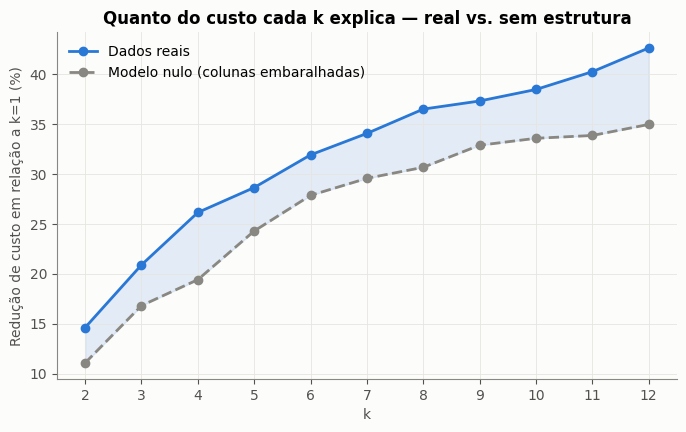

In [14]:
ks = res_k.index
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(ks, res_k["reducao_real"] * 100, marker="o", color=AZUL, label="Dados reais")
ax.plot(ks, res_k["reducao_nula"] * 100, marker="o", color=CINZA, linestyle="--", label="Modelo nulo (colunas embaralhadas)")
ax.fill_between(ks, res_k["reducao_nula"] * 100, res_k["reducao_real"] * 100, color=AZUL, alpha=0.12)
ax.set_xlabel("k")
ax.set_ylabel("Redução de custo em relação a k=1 (%)")
ax.set_title("Quanto do custo cada k explica — real vs. sem estrutura")
ax.set_xticks(ks)
ax.legend(frameon=False, loc="upper left")
salvar("02_custo_vs_nulo")
plt.show()

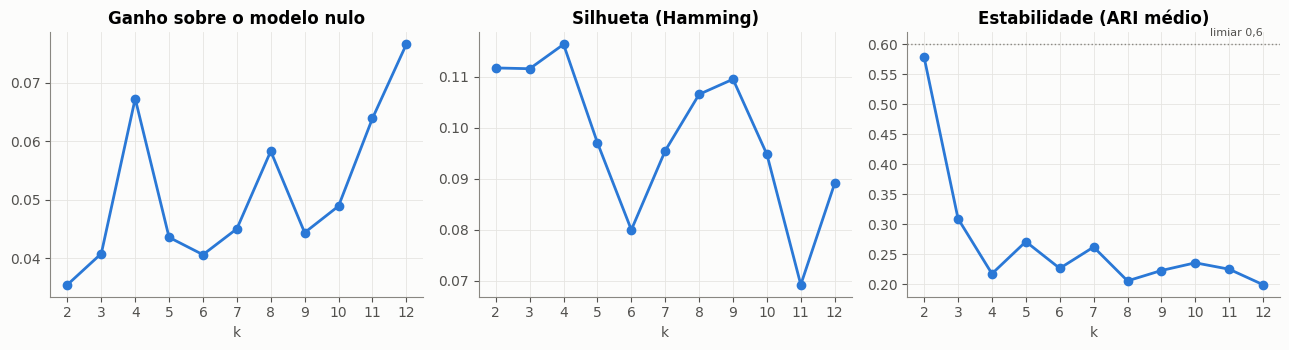

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), sharex=True)
for ax, col, titulo in zip(axes, ["ganho_sobre_nulo", "silhueta", "ari"],
                           ["Ganho sobre o modelo nulo", "Silhueta (Hamming)", "Estabilidade (ARI médio)"]):
    ax.plot(ks, res_k[col], marker="o", color=AZUL)
    ax.set_title(titulo)
    ax.set_xticks(ks)
    ax.set_xlabel("k")
axes[2].axhline(0.6, color=CINZA, linestyle=":", linewidth=1)
axes[2].text(ks[-1], 0.61, "limiar 0,6", ha="right", va="bottom", color=TINTA2, fontsize=8)
plt.tight_layout()
salvar("03_metricas_k")
plt.show()

### 4.1 Regra de decisão

Entre os valores de k com partição estável (ARI ≥ 0,6), escolhe-se o de **maior ganho sobre o modelo nulo**. Atenção: k=2 costuma ser o mais estável simplesmente por ser a partição mais grosseira. Se a regra devolver 2, vale olhar a tabela e ver se algum k maior tem ARI próximo do limiar e ganho claramente maior. Se nenhum for estável, usa-se o joelho da curva, e o resultado deve ser reportado como **ausência de estrutura robusta**, que é um resultado válido para o trabalho (relatório, Seção 10, item 3).

`K_FINAL` pode ser sobrescrito manualmente, desde que a justificativa seja registrada.

In [16]:
estaveis = res_k[res_k["ari"] >= 0.6]
if len(estaveis):
    K_FINAL = int(estaveis["ganho_sobre_nulo"].idxmax())
    motivo = "maior ganho sobre o nulo entre os k estáveis"
else:
    K_FINAL = joelho(list(res_k.index), list(res_k["custo_huang"]))
    motivo = "nenhum k estável; usado o joelho da curva"
INIT_FINAL = res_k.loc[K_FINAL, "init"]
print(f"K_FINAL = {K_FINAL} ({motivo}); init = {INIT_FINAL}")
print(f"Ganho sobre o nulo em k={K_FINAL}: {res_k.loc[K_FINAL, 'ganho_sobre_nulo']:.3f} "
      f"| silhueta: {res_k.loc[K_FINAL, 'silhueta']:.3f} | ARI: {res_k.loc[K_FINAL, 'ari']:.2f}")

K_FINAL = 6 (nenhum k estável; usado o joelho da curva); init = Huang
Ganho sobre o nulo em k=6: 0.041 | silhueta: 0.080 | ARI: 0.23


## 5. Modelo final

Ajustado na amostra de trabalho inteira, e não só na subamostra da busca.

In [17]:
X = df[FEATS].to_numpy()
km = ajustar(X, K_FINAL, INIT_FINAL)
df["CLUSTER"] = km.labels_
print(f"Custo: {km.cost_:,.0f} | iterações: {km.n_iter_}")

tamanhos = df["CLUSTER"].value_counts().sort_index()
centroides = pd.DataFrame(km.cluster_centroids_, columns=FEATS)
centroides.insert(0, "n", tamanhos.values)
centroides.insert(1, "%", (tamanhos.values / len(df) * 100).round(1))
centroides

Custo: 101,251 | iterações: 5


,n,%,CRIME,LOCAL,ARMA,PERIODO,DIA
0,13039,26.1,VEHICLE - STOLEN,STREET,SEM_ARMA,MANHA,FIM_DE_SEMANA
1,8898,17.8,INTIMATE PARTNER - SIMPLE ASSAULT,"MULTI-UNIT DWELLING (APARTMENT, DUPLEX, ETC)",FORCA_FISICA,TARDE,DIA_UTIL
2,2565,5.1,BATTERY - SIMPLE ASSAULT,PARKING LOT,FORCA_FISICA,TARDE,FIM_DE_SEMANA
3,11830,23.7,VEHICLE - STOLEN,STREET,SEM_ARMA,NOITE,DIA_UTIL
4,6694,13.4,BURGLARY,SINGLE FAMILY DWELLING,SEM_ARMA,MADRUGADA,DIA_UTIL
5,6974,13.9,OUTROS,OUTROS,SEM_ARMA,TARDE,DIA_UTIL


### 5.1 Pureza e AMI por atributo

A **pureza** é a fração do cluster que tem o mesmo valor do centroide naquele atributo. Um centroide com pureza baixa é uma moda fraca e não descreve o cluster.

A **AMI** é o diagnóstico já usado no relatório: mostra quais atributos de fato formaram a partição.

,CRIME,LOCAL,ARMA,PERIODO,DIA
CLUSTER,,,,,
0,0.16,0.38,0.79,0.46,0.73
1,0.26,0.37,0.70,0.49,0.90
2,0.52,0.24,0.73,0.49,0.94
3,0.26,0.52,0.83,0.73,1.00
4,0.28,0.60,0.86,0.50,0.91
5,0.29,0.60,0.85,0.74,0.88


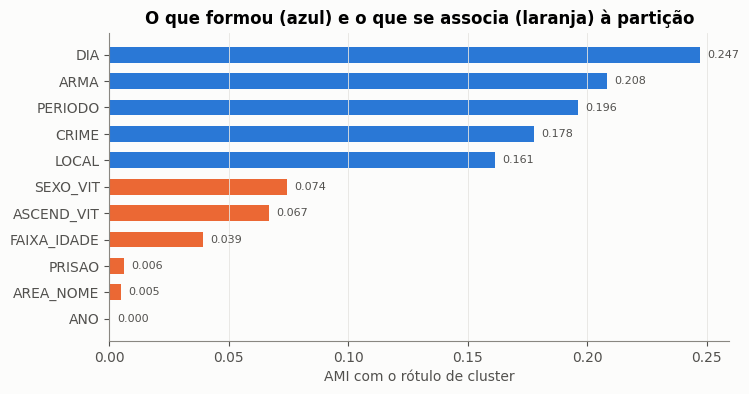

In [18]:
pureza = pd.DataFrame({c: [(df.loc[df.CLUSTER == g, c] == centroides.loc[g, c]).mean() for g in range(K_FINAL)]
                       for c in FEATS})
pureza.index.name = "CLUSTER"
display(pureza.round(2))

ami = pd.Series({c: adjusted_mutual_info_score(df[c], df["CLUSTER"]) for c in FEATS + DESCRITIVAS})
fig, ax = plt.subplots(figsize=(8, 4))
ordem = ami.sort_values()
ax.barh(ordem.index, ordem.values, color=[AZUL if c in FEATS else LARANJA for c in ordem.index], height=0.6)
ax.set_xlabel("AMI com o rótulo de cluster")
ax.set_title("O que formou (azul) e o que se associa (laranja) à partição")
ax.grid(axis="y", visible=False)
for y, v in enumerate(ordem.values):
    ax.text(v + 0.003, y, f"{v:.3f}", va="center", color=TINTA2, fontsize=8)
salvar("04_ami")
plt.show()

## 6. Perfis dos clusters por *lift*

As barras empilhadas da versão anterior mostravam contagens absolutas, dominadas pelas categorias mais frequentes da base. O **lift** compara a frequência de uma categoria dentro do cluster com a frequência na base toda:

$$\text{lift}(c, g) = \frac{P(c \mid g)}{P(c)}$$

Lift 3 significa que a categoria é três vezes mais comum no cluster que na base. No mapa de calor, a escala é $\log_2$: azul = sub-representada, vermelho = sobre-representada, cinza = igual à média.

In [19]:
def tabela_lift(dados, col, grupo="CLUSTER"):
    p_c = dados[col].value_counts(normalize=True)
    p_cg = pd.crosstab(dados[grupo], dados[col], normalize="index")
    return p_cg / p_c

def perfil(dados, grupo="CLUSTER", cols=FEATS, top=3, suporte_min=0.05):
    # Top categorias por lift em cada cluster, exigindo presença mínima no cluster
    saida = {}
    for g in sorted(dados[grupo].unique()):
        itens = []
        for c in cols:
            p = dados.loc[dados[grupo] == g, c].value_counts(normalize=True)
            l = tabela_lift(dados, c, grupo).loc[g]
            cand = l[p.reindex(l.index).fillna(0) >= suporte_min].sort_values(ascending=False)
            itens += [f"{c}={v} ({lf:.1f}×, {p[v]:.0%})" for v, lf in cand.head(top).items() if lf > 1.2]
        saida[g] = itens
    return pd.DataFrame({"n": dados[grupo].value_counts().sort_index(),
                         "destaques (lift, % no cluster)": ["; ".join(v[:6]) for v in saida.values()]})

with pd.option_context("display.max_colwidth", None):
    display(perfil(df))

,n,"destaques (lift, % no cluster)"
CLUSTER,,
0,13039,"CRIME=THEFT FROM MOTOR VEHICLE - PETTY ($950 & UNDER) (1.6×, 6%); CRIME=VEHICLE - STOLEN (1.5×, 16%); CRIME=BURGLARY FROM VEHICLE (1.4×, 9%); LOCAL=STREET (1.5×, 38%); ARMA=SEM_ARMA (1.2×, 79%); PERIODO=MANHA (2.2×, 46%)"
1,8898,"CRIME=INTIMATE PARTNER - SIMPLE ASSAULT (5.1×, 26%); CRIME=BATTERY - SIMPLE ASSAULT (3.1×, 25%); CRIME=ROBBERY (2.0×, 7%); LOCAL=MULTI-UNIT DWELLING (APARTMENT, DUPLEX, ETC) (3.0×, 37%); LOCAL=SIDEWALK (2.1×, 9%); ARMA=FORCA_FISICA (3.8×, 70%)"
2,2565,"CRIME=BATTERY - SIMPLE ASSAULT (6.5×, 52%); CRIME=ROBBERY (2.4×, 8%); CRIME=ASSAULT WITH DEADLY WEAPON, AGGRAVATED ASSAULT (1.6×, 9%); LOCAL=PARKING LOT (3.4×, 24%); LOCAL=SIDEWALK (2.9×, 12%); ARMA=FORCA_FISICA (3.9×, 73%)"
3,11830,"CRIME=VEHICLE - STOLEN (2.5×, 26%); CRIME=THEFT FROM MOTOR VEHICLE - PETTY ($950 & UNDER) (1.9×, 7%); CRIME=THEFT FROM MOTOR VEHICLE - GRAND ($950.01 AND OVER) (1.8×, 6%); LOCAL=STREET (2.1×, 52%); ARMA=ARMA_DE_FOGO (1.3×, 6%); ARMA=SEM_ARMA (1.3×, 83%)"
4,6694,"CRIME=BURGLARY (4.6×, 28%); CRIME=THEFT OF IDENTITY (3.2×, 21%); LOCAL=SINGLE FAMILY DWELLING (3.6×, 60%); ARMA=SEM_ARMA (1.3×, 86%); PERIODO=MADRUGADA (3.2×, 50%); DIA=DIA_UTIL (1.3×, 91%)"
5,6974,"CRIME=SHOPLIFTING - PETTY THEFT ($950 & UNDER) (3.4×, 8%); CRIME=OUTROS (2.9×, 29%); CRIME=THEFT PLAIN - PETTY ($950 & UNDER) (2.3×, 12%); LOCAL=OUTROS (3.4×, 60%); LOCAL=OTHER BUSINESS (1.7×, 8%); ARMA=SEM_ARMA (1.3×, 85%)"


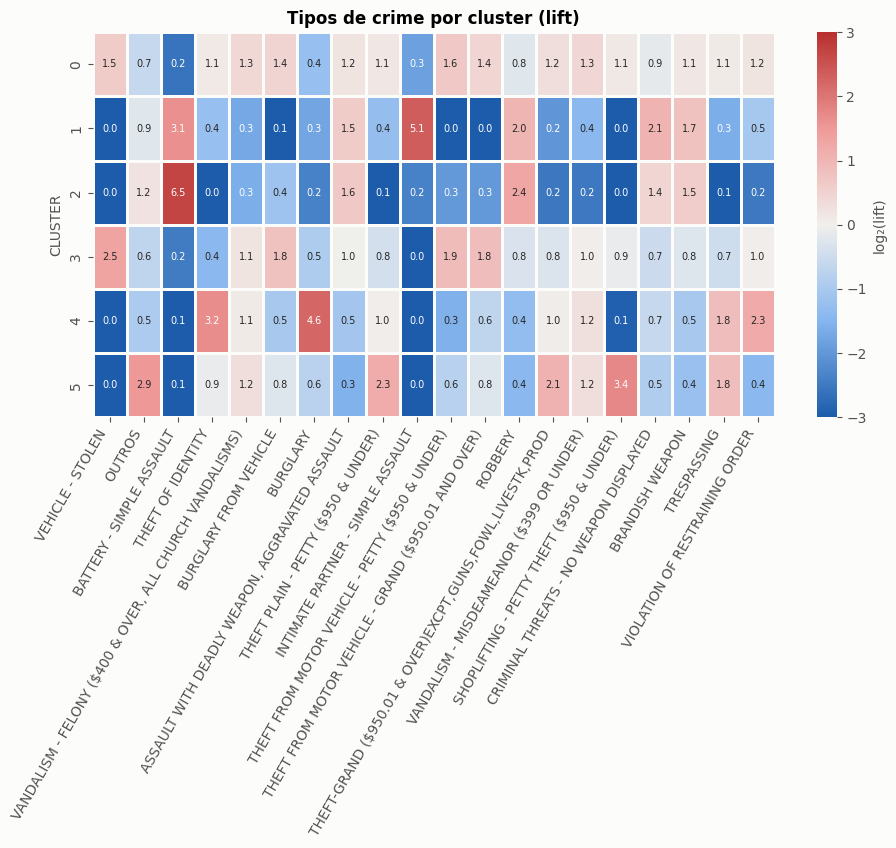

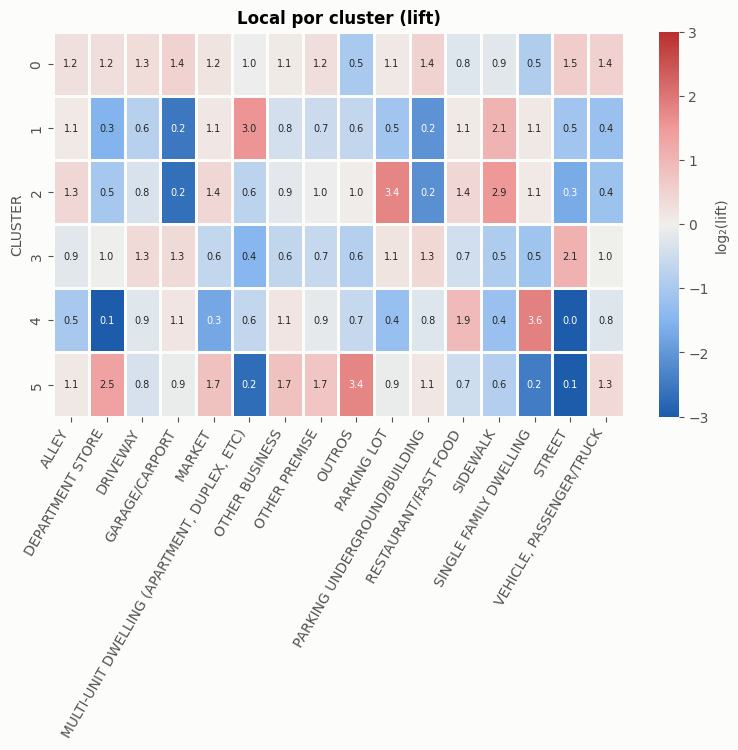

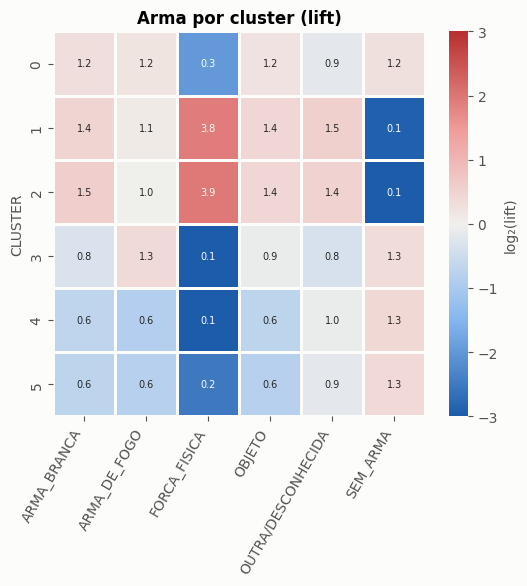

In [20]:
def heatmap_lift(dados, col, top=None, titulo=None, nome=None, grupo="CLUSTER"):
    l = tabela_lift(dados, col, grupo)
    if top:
        l = l[dados[col].value_counts().index[:top]]
    l2 = np.log2(l.clip(lower=1 / 8)).clip(-3, 3)   # lift 0 (categoria ausente no cluster) aparece no extremo azul
    fig, ax = plt.subplots(figsize=(max(6, 0.45 * l2.shape[1] + 2), 0.5 * l2.shape[0] + 2))
    sns.heatmap(l2, cmap=DIV, center=0, vmin=-3, vmax=3, linewidths=2, linecolor="#fcfcfb",
                annot=l.round(1), fmt="", annot_kws={"fontsize": 7}, cbar_kws={"label": "log₂(lift)"}, ax=ax)
    ax.set_title(titulo or f"{col} por cluster (lift)")
    ax.set_xlabel(""); ax.grid(False)
    plt.xticks(rotation=60, ha="right")
    if nome: salvar(nome)
    plt.show()

heatmap_lift(df, "CRIME", top=20, titulo="Tipos de crime por cluster (lift)", nome="05_lift_crime")
heatmap_lift(df, "LOCAL", titulo="Local por cluster (lift)", nome="06_lift_local")
heatmap_lift(df, "ARMA", titulo="Arma por cluster (lift)", nome="07_lift_arma")

## 7. Associação *a posteriori* com área, vítima e desfecho (PP2)

Como a demografia **não** entrou no agrupamento, qualquer associação encontrada aqui não é circular: ela diz se perfis de fato criminal se distribuem de forma desigual entre áreas e perfis de vítima.

Como no relatório, com n desta ordem o p-valor é sempre ~0. A leitura se apoia no **tamanho de efeito** (V de Cramér e AMI) e nos **resíduos padronizados ajustados**, que mostram *quais células* concentram a associação. Um |resíduo| > 2 indica desvio relevante naquela combinação.

In [21]:
assoc = pd.DataFrame({
    "V_cramer": [cramers_v(df["CLUSTER"], df[c]) for c in DESCRITIVAS],
    "AMI": [adjusted_mutual_info_score(df[c], df["CLUSTER"]) for c in DESCRITIVAS],
}, index=DESCRITIVAS).sort_values("V_cramer", ascending=False)
assoc.round(3)

,V_cramer,AMI
SEXO_VIT,0.252,0.074
ASCEND_VIT,0.205,0.067
FAIXA_IDADE,0.153,0.039
PRISAO,0.117,0.006
AREA_NOME,0.065,0.005
ANO,0.018,0.000


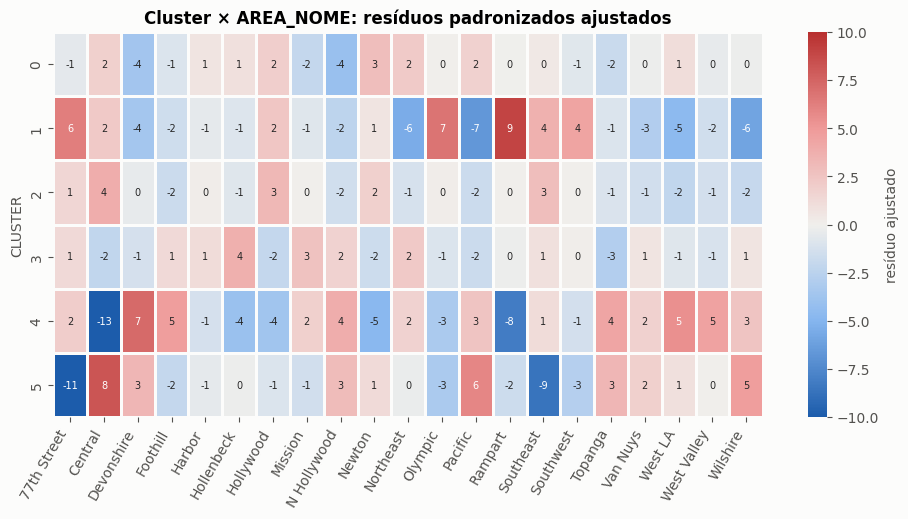

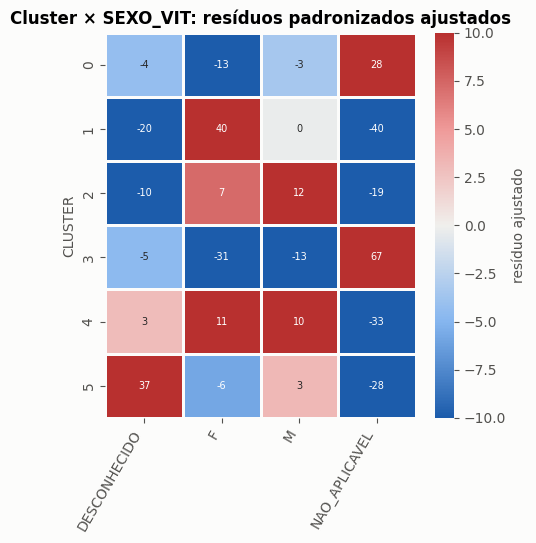

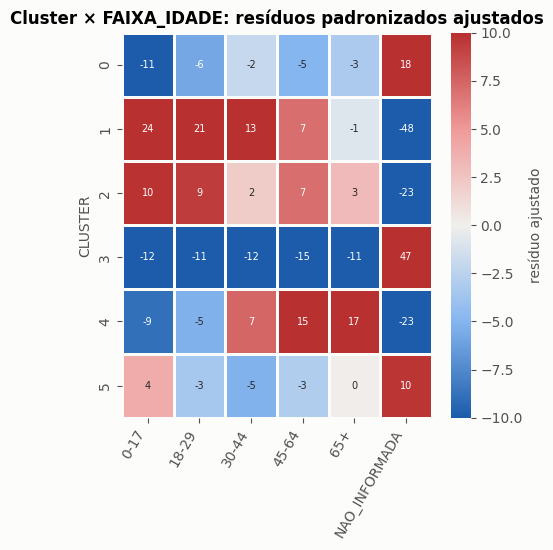

In [22]:
def residuos_ajustados(x, y):
    tab = pd.crosstab(x, y)
    n = tab.values.sum()
    esp = chi2_contingency(tab, correction=False)[3]
    pr, pc = tab.sum(axis=1).values[:, None] / n, tab.sum(axis=0).values[None, :] / n
    return pd.DataFrame((tab.values - esp) / np.sqrt(esp * (1 - pr) * (1 - pc)), index=tab.index, columns=tab.columns)

for col, nome in [("AREA_NOME", "08_residuos_area"), ("SEXO_VIT", "09_residuos_sexo"), ("FAIXA_IDADE", "10_residuos_idade")]:
    r = residuos_ajustados(df["CLUSTER"], df[col])
    fig, ax = plt.subplots(figsize=(max(5, 0.45 * r.shape[1] + 2), 0.5 * r.shape[0] + 2))
    lim = min(10, np.nanmax(np.abs(r.values)))
    sns.heatmap(r.clip(-lim, lim), cmap=DIV, center=0, vmin=-lim, vmax=lim, linewidths=2, linecolor="#fcfcfb",
                annot=r.round(0).astype(int), fmt="d", annot_kws={"fontsize": 7}, cbar_kws={"label": "resíduo ajustado"}, ax=ax)
    ax.set_title(f"Cluster × {col}: resíduos padronizados ajustados")
    ax.set_xlabel(""); ax.grid(False)
    plt.xticks(rotation=60, ha="right")
    salvar(nome)
    plt.show()

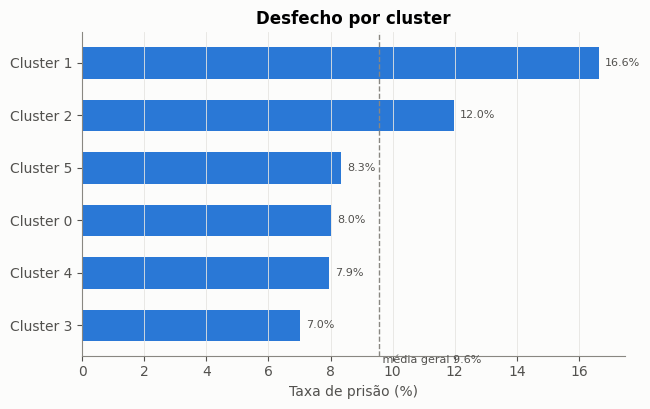

In [23]:
taxa = df.groupby("CLUSTER")["PRISAO"].apply(lambda s: (s == "PRISAO").mean() * 100).sort_values()
geral = (df["PRISAO"] == "PRISAO").mean() * 100
fig, ax = plt.subplots(figsize=(7, 0.45 * len(taxa) + 1.5))
ax.barh([f"Cluster {g}" for g in taxa.index], taxa.values, color=AZUL, height=0.6)
ax.axvline(geral, color=CINZA, linestyle="--", linewidth=1)
ax.text(geral, -0.75, f" média geral {geral:.1f}%", color=TINTA2, fontsize=8, va="bottom")
for y, v in enumerate(taxa.values):
    ax.text(v + 0.2, y, f"{v:.1f}%", va="center", color=TINTA2, fontsize=8)
ax.set_xlabel("Taxa de prisão (%)")
ax.set_title("Desfecho por cluster")
ax.grid(axis="y", visible=False)
salvar("11_prisao_cluster")
plt.show()

## 8. Sensibilidade

Duas checagens rápidas de robustez:

- **Exclusão de atributo** (*leave-one-feature-out*): refaz o agrupamento sem cada atributo e mede o ARI com a partição final. ARI alto ao remover um atributo = ele pouco contribuiu.
- **Sem o corte de 2024**: não é refeito aqui, para não baixar a base de novo. Se o grupo quiser, basta mudar `DATA_CORTE` e comparar os perfis.

In [24]:
X_s, lab_s = X_busca, km.predict(X_busca)
sens = {}
for c in FEATS:
    cols = [i for i, f in enumerate(FEATS) if f != c]
    km_s = KModes(n_clusters=K_FINAL, init="Huang", n_init=3, random_state=SEED, n_jobs=-1).fit(X_s[:, cols])
    sens[c] = adjusted_rand_score(lab_s, km_s.labels_)
pd.Series(sens, name="ARI sem o atributo").sort_values().round(3).to_frame()

,ARI sem o atributo
ARMA,0.182
DIA,0.203
PERIODO,0.261
LOCAL,0.305
CRIME,0.459


## 9. Modus operandi (`Mocodes`)

`Mocodes` é o campo com mais informação comportamental da base, mas no K-Modes virava uma string quase única (E3). Aqui ele é tratado como **texto**:

1. cada código de 4 dígitos vira um *token*;
2. **TF-IDF** dá menos peso a códigos muito comuns (ex.: "suspeito desconhecido");
3. **SVD truncado** (LSA) reduz para 20 dimensões;
4. **K-Means** com escolha de k por silhueta (cosseno).

Se o arquivo opcional `data/raw/mo_codes.csv` existir (colunas `codigo,descricao`, transcritas da tabela oficial de MO codes do LAPD), os códigos aparecem com a descrição.

Registros com Mocodes: 86.3%
Vocabulário mantido (≥0,5% dos registros): 97 códigos
Variância explicada pelo SVD: 55.8%


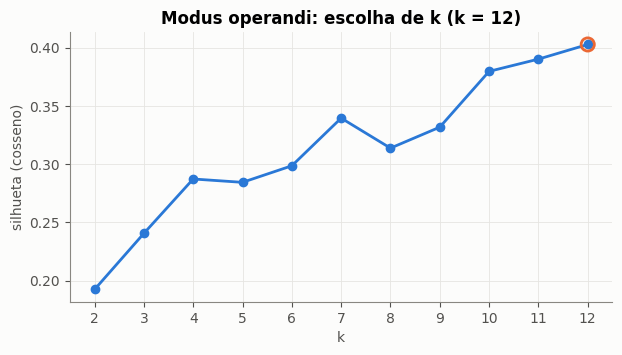

In [25]:
mo = df["Mocodes"].fillna("").str.strip()
tem_mo = mo.str.len() > 0
print(f"Registros com Mocodes: {tem_mo.mean():.1%}")

tfidf = TfidfVectorizer(token_pattern=r"\b\d{4}\b", min_df=0.005)
M = tfidf.fit_transform(mo[tem_mo])
print(f"Vocabulário mantido (≥0,5% dos registros): {M.shape[1]} códigos")

svd = TruncatedSVD(n_components=min(20, M.shape[1] - 1), random_state=SEED)
Z = Normalizer().fit_transform(svd.fit_transform(M))
print(f"Variância explicada pelo SVD: {svd.explained_variance_ratio_.sum():.1%}")

sub = rng.choice(len(Z), size=min(N_SILHUETA, len(Z)), replace=False)
sil_mo = {}
for k in range(2, 13):
    lab = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit_predict(Z)
    sil_mo[k] = silhouette_score(Z[sub], lab[sub], metric="cosine")
K_MO = max(sil_mo, key=sil_mo.get)

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(list(sil_mo), list(sil_mo.values()), marker="o", color=AZUL)
ax.scatter([K_MO], [sil_mo[K_MO]], s=90, facecolor="none", edgecolor=LARANJA, linewidth=2, zorder=3)
ax.set_xticks(list(sil_mo)); ax.set_xlabel("k"); ax.set_ylabel("silhueta (cosseno)")
ax.set_title(f"Modus operandi: escolha de k (k = {K_MO})")
salvar("12_silhueta_mo")
plt.show()

In [26]:
km_mo = KMeans(n_clusters=K_MO, n_init=20, random_state=SEED).fit(Z)
df["CLUSTER_MO"] = "SEM_MO"
df.loc[tem_mo, "CLUSTER_MO"] = "MO_" + pd.Series(km_mo.labels_, index=mo[tem_mo].index).astype(str)

desc_mo = {}
if os.path.exists(CAMINHO_MO):
    t = pd.read_csv(CAMINHO_MO, dtype=str)
    desc_mo = dict(zip(t["codigo"].str.zfill(4), t["descricao"]))

# Códigos mais característicos: centroide reprojetado no espaço TF-IDF
termos = tfidf.get_feature_names_out()
proj = svd.inverse_transform(km_mo.cluster_centers_)
linhas = []
for g in range(K_MO):
    mask = (df["CLUSTER_MO"] == f"MO_{g}")
    top_codes = [termos[i] for i in np.argsort(proj[g])[::-1][:6]]
    crimes = df.loc[mask, "CRIME"].value_counts(normalize=True).head(3)
    linhas.append({
        "cluster": f"MO_{g}", "n": int(mask.sum()),
        "códigos MO característicos": ", ".join(f"{c} {desc_mo.get(c, '')}".strip() for c in top_codes),
        "crimes mais comuns": "; ".join(f"{c} ({p:.0%})" for c, p in crimes.items()),
    })
with pd.option_context("display.max_colwidth", None):
    display(pd.DataFrame(linhas).set_index("cluster"))

,n,códigos MO característicos,crimes mais comuns
cluster,,,
MO_0,6113,"0344, 1822, 1606, 2032, 0321, 0377","THEFT PLAIN - PETTY ($950 & UNDER) (22%); BURGLARY (20%); THEFT-GRAND ($950.01 & OVER)EXCPT,GUNS,FOWL,LIVESTK,PROD (17%)"
MO_1,4183,"2000, 1814, 0913, 0416, 0444, 1813",INTIMATE PARTNER - SIMPLE ASSAULT (58%); INTIMATE PARTNER - AGGRAVATED ASSAULT (15%); OUTROS (6%)
MO_2,4104,"1822, 1309, 0334, 1402, 0421, 0342","OUTROS (23%); ASSAULT WITH DEADLY WEAPON, AGGRAVATED ASSAULT (21%); THEFT OF IDENTITY (13%)"
MO_3,3856,"0913, 2038, 0334, 0421, 0432, 0603",OUTROS (22%); CRIMINAL THREATS - NO WEAPON DISPLAYED (13%); BATTERY - SIMPLE ASSAULT (13%)
MO_4,2294,"0100, 0930, 1822, 0922, 0929, 0377","THEFT OF IDENTITY (95%); OUTROS (2%); BUNCO, GRAND THEFT (1%)"
MO_5,4299,"0416, 0400, 0913, 1822, 0446, 2004","BATTERY - SIMPLE ASSAULT (58%); ASSAULT WITH DEADLY WEAPON, AGGRAVATED ASSAULT (20%); OUTROS (9%)"
MO_6,3539,"0329, 1822, 0344, 1307, 1402, 1202","VANDALISM - FELONY ($400 & OVER, ALL CHURCH VANDALISMS) (56%); VANDALISM - MISDEAMEANOR ($399 OR UNDER) (25%); BURGLARY (8%)"
MO_7,5031,"0344, 2004, 1202, 1402, 1822, 0385",OUTROS (15%); THEFT PLAIN - PETTY ($950 & UNDER) (15%); THEFT FROM MOTOR VEHICLE - GRAND ($950.01 AND OVER) (13%)
MO_8,3762,"1300, 0344, 0329, 1822, 0385, 1606","VANDALISM - FELONY ($400 & OVER, ALL CHURCH VANDALISMS) (21%); BURGLARY FROM VEHICLE (20%); THEFT FROM MOTOR VEHICLE - GRAND ($950.01 AND OVER) (18%)"


ARI  K-Modes × MO: 0.058
AMI  K-Modes × MO: 0.102


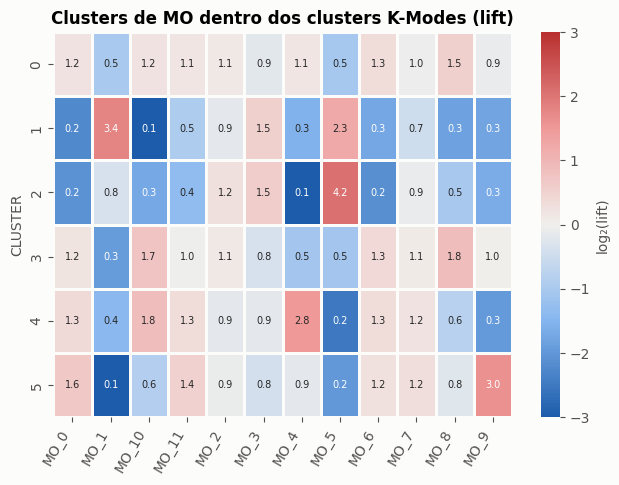

In [27]:
# Os dois agrupamentos capturam a mesma coisa? ARI/AMI entre eles (só registros com Mocodes)
m = df["CLUSTER_MO"] != "SEM_MO"
print(f"ARI  K-Modes × MO: {adjusted_rand_score(df.loc[m, 'CLUSTER'], df.loc[m, 'CLUSTER_MO']):.3f}")
print(f"AMI  K-Modes × MO: {adjusted_mutual_info_score(df.loc[m, 'CLUSTER'], df.loc[m, 'CLUSTER_MO']):.3f}")
heatmap_lift(df[m], "CLUSTER_MO", titulo="Clusters de MO dentro dos clusters K-Modes (lift)", nome="13_lift_mo_kmodes")

## 10. Exportação

Salva a amostra com os rótulos (inclui `LAT` e `LON`, usadas no mapa do notebook 03) e as tabelas de métricas, para o relatório e para o notebook de visualizações.

In [28]:
cols_saida = ["DR_NO", "DATA_OCC"] + FEATS + DESCRITIVAS + ["CLUSTER", "CLUSTER_MO", "LAT", "LON"]
df[cols_saida].to_csv(f"{DIR_PROCESSADOS}/amostra_clusters.csv", index=False)
res_k.to_csv(f"{DIR_PROCESSADOS}/metricas_escolha_k.csv")
assoc.to_csv(f"{DIR_PROCESSADOS}/associacao_clusters.csv")
print("Arquivos salvos em", DIR_PROCESSADOS, "e figuras em", DIR_FIGURAS)

Arquivos salvos em data/processed e figuras em docs/figuras


## 11. Como ler os resultados (roteiro para o relatório)

1. **Existe estrutura?** Olhe o gráfico real × nulo (Seção 4). Se as curvas estão próximas e a silhueta fica perto de 0, a conclusão do relatório parcial se confirma com evidência formal: os registros não formam grupos naturais nesse espaço de atributos. Reporte isso como resultado, não como falha.
2. **Se existe, é estável?** ARI ≥ 0,6 no k escolhido.
3. **O que define cada cluster?** Tabela de perfis por lift e pureza (Seções 5–6). Só nomeie um cluster como "perfil" se a pureza do atributo principal for alta.
4. **PP2:** V de Cramér e resíduos da Seção 7. Como a demografia não entrou no modelo, esses números medem associação real entre perfil do fato e perfil da vítima ou área.
5. **Limitação:** as variáveis de vítima descrevem **vítimas**, não autores, e os dados são **registros policiais**, não criminalidade (relatório, Seção 9).